# 02 · 真实运行的能谱与时间差分析

这个 Notebook 从本地 **DT5730_DPP_PSD / run0009 的排序 ROOT 文件**重新构建事件，按通道绘制能谱、施加能量门、拟合峰形，并保存可以追溯的结果。默认参数对应当前样本；可以编辑代码并自行运行。

在 Jupyter Notebook 中选择 **LaBr3 (PyROOT)** 内核，使用 **Kernel → Restart & Run All**，或从第一格起按 `Shift+Enter`。需要 PyROOT、NumPy、Matplotlib、Make、C++ 编译器及 Git，当前系统已经具备；不需要 SciPy。输入的 ROOT 数据留在本机，不随 Git 分发。

**数据解释的前提：**当前排序文件的历史刻度与时间偏移来源尚未确认，因此能量只标为“存储单位”。本流程从已有排序结果开始，未重跑 BIN 解码或排序；上游的板号和时间精度问题仍需后续修复。目录名仅标识文件来源，不能替代实验记录。

In [1]:
from pathlib import Path
import sys
import json
import html
import platform
from IPython.display import display, HTML, Markdown

# Set an absolute path here if the kernel starts outside this project.
PROJECT_DIR = None
if PROJECT_DIR is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_DIR = next((p for p in candidates if (p / "analysis/EventAnalysis.h").is_file()), None)
    if PROJECT_DIR is None:
        raise FileNotFoundError("Set PROJECT_DIR to the LaBr3 repository directory")
PROJECT_DIR = Path(PROJECT_DIR).resolve()
sys.path.insert(0, str(PROJECT_DIR))

import ROOT
import numpy as np
import matplotlib.pyplot as plt
from analysis import notebook_analysis as analysis
ROOT.gROOT.SetBatch(True)
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# Restart the kernel after editing the Python module or C++ header.
def table(headers, rows):
    heading = "".join(f"<th>{html.escape(str(x))}</th>" for x in headers)
    body = "".join("<tr>" + "".join(f"<td>{html.escape(str(x))}</td>" for x in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>"))

print("Project:", PROJECT_DIR)
print("Python:", platform.python_version(), "ROOT:", ROOT.gROOT.GetVersion())

Project: /media/sf_works/LaBr3
Python: 3.14.4 ROOT: 6.40.04


## 1. 可修改参数

`gates_a` 内多个窗口取并集，`gates_b` 内也取并集，然后要求 A、B **同时**通过；边界使用严格的 `low < energy < high`。每个列表设为 `[]` 表示该通道不施加能量门。以下窗口沿用旧 PSD 分析宏，只作为可修改的分析起点，未确认其对应的物理峰。

仅分析 `m == 2` 且确实包含指定通道对的时间差，方向恒为 **t_B − t_A**，与记录排列无关。板号 `-1` 表示不限板号；当前文件存储的板号为 0，上游是否正确保留了采集板号尚未验证。单通道能谱包含所有事件中的命中。

拟合端点须落在直方图边界上：当前能量 bin 宽为 2，时间 bin 宽为 0.1 ns。若修改分箱，也要调整拟合端点。切换运行时请同时调整能量门、峰名和拟合区间。

In [2]:
DEVICE = "DT5730_DPP_PSD"
RUN = 9
SORTED_INPUT = PROJECT_DIR / DEVICE / "sort" / f"run{RUN:04d}_sort.root"
HISTORICAL_BUILT = PROJECT_DIR / DEVICE / "build" / f"run{RUN:04d}_build.root"
OUTPUT_ROOT = PROJECT_DIR / "results"

SETTINGS = {
    "channel_a": 2, "channel_b": 3,
    "board_a": 0, "board_b": 0,
    "gates_a": [[592, 611], [674, 693]],
    "gates_b": [[1105, 1137], [1253, 1290]],
    "energy_bins": 2048, "energy_low": 0., "energy_high": 4096.,
    "time_bins": 1000, "time_low": -50., "time_high": 50.,
}
# These are local peak-core examples, chosen after inspecting this run.
ENERGY_PEAKS = [
    {"name": "ch2_peak1", "spectrum": "board0_ch2", "range": [590, 614]},
    {"name": "ch2_peak2", "spectrum": "board0_ch2", "range": [670, 696]},
    {"name": "ch3_peak1", "spectrum": "board0_ch3", "range": [1100, 1144]},
    {"name": "ch3_peak2", "spectrum": "board0_ch3", "range": [1250, 1296]},
]
TIME_FIT_RANGE = [-9.5, -5.5]
TIME_RANGE_CHECKS = [[-9., -6.], [-9.5, -5.5], [-10., -5.]]

analysis.make_config(SETTINGS)  # Fail early on invalid channels, gates, or ranges.
print(json.dumps(SETTINGS, indent=2))

{
  "channel_a": 2,
  "channel_b": 3,
  "board_a": 0,
  "board_b": 0,
  "gates_a": [
    [
      592,
      611
    ],
    [
      674,
      693
    ]
  ],
  "gates_b": [
    [
      1105,
      1137
    ],
    [
      1253,
      1290
    ]
  ],
  "energy_bins": 2048,
  "energy_low": 0.0,
  "energy_high": 4096.0,
  "time_bins": 1000,
  "time_low": -50.0,
  "time_high": 50.0
}


## 2. 检查输入，并用当前源码重新构建事件

事件以第一条记录为基准，严格小于 **50 ns** 的后续记录归入同一事件；最多允许 8 重。对输入进行 SHA-256 标识，并保存本次使用的源码、参数文件快照及编译日志。现有 `.dat` 文件的快照是当前配置参考，**不是**历史排序文件曾使用这些配置的证明。

每次从头运行都创建独立的 `results/设备_run编号_时间_随机标识/`，保留原排序和旧事件文件。重新执行后续单元会更新本次结果目录。大数组遍历在共享 C++ 分析代码中完成，Python 单元负责配置、拟合、绘图和结果导出。

In [3]:
if not SORTED_INPUT.is_file():
    raise FileNotFoundError(f"Local sorted input is required: {SORTED_INPUT}")
print("Input tree:", analysis.tree_info(SORTED_INPUT))
BUILT_INPUT, OUTPUT_DIR, PROVENANCE = analysis.rebuild_events(SORTED_INPUT, DEVICE, RUN, OUTPUT_ROOT)
print("Sorted hits:", f'{PROVENANCE["input_sorted"]["entries"]:,}')
print("Rebuilt events:", f'{PROVENANCE["rebuilt"]["entries"]:,}')
print("Input SHA-256:", PROVENANCE["input_sorted"]["sha256"])
print("Output directory:", OUTPUT_DIR)
print("Build time (s):", round(PROVENANCE["build_elapsed_seconds"], 2))

Input tree: {'entries': 3096191, 'title': 'DT5730_DPP_PSD', 'branches': {'board': 'Short_t', 'channel': 'Short_t', 'energy': 'Double_t', 'timestamp': 'Long64_t'}}


Sorted hits: 3,096,191
Rebuilt events: 3,044,359
Input SHA-256: 472ccf4350845212f5d80762f278e259398ba9468bf3a649ca5188d05532a83a
Output directory: /media/sf_works/LaBr3/results/DT5730_DPP_PSD_run0009_20260928T090457Z_0q6xqbwn
Build time (s): 4.94


## 3. 分析计数与记录守恒

安全读取可变长度数组，先验证多重数及数据类型，再处理事件。历史文件仅用于比较，不作为正确结果的判据。当前运行预期能看到末事件补写带来的变化；代码不把本次测得的数量硬编码为其他运行的标准。

In [4]:
RESULT = analysis.analyze_events(BUILT_INPUT, SETTINGS)
COUNTS = analysis.event_summary(RESULT)
SPECTRA = analysis.histograms(RESULT)
assert COUNTS["hits"] == PROVENANCE["input_sorted"]["entries"], "Hit conservation failed"
assert sum(COUNTS["multiplicities"].values()) == COUNTS["events"]
assert sum(int(m) * count for m, count in COUNTS["multiplicities"].items()) == COUNTS["hits"]
assert COUNTS["selected_times"]["entries"] == COUNTS["selected_pairs"]
assert sum(item["entries"] for item in COUNTS["spectra"].values()) == COUNTS["hits"]

rows = [["排序输入命中", PROVENANCE["input_sorted"]["entries"]],
        ["重建事件", COUNTS["events"]], ["重建命中", COUNTS["hits"]],
        ["指定通道的双重事件", COUNTS["channel_pairs"]],
        ["通过能量门", COUNTS["selected_pairs"]]]
HISTORICAL = None
if HISTORICAL_BUILT.is_file():
    HISTORICAL = {**analysis.file_identity(HISTORICAL_BUILT), **analysis.old_event_counts(HISTORICAL_BUILT)}
    rows += [["历史事件", HISTORICAL["events"]], ["历史命中", HISTORICAL["hits"]],
             ["新旧命中差", COUNTS["hits"] - HISTORICAL["hits"]]]
table(["项目", "数量"], rows)
table(["多重数", "事件数"], COUNTS["multiplicities"].items())
table(["直方图", "总数", "范围内", "下溢", "上溢"],
      [[name, *[item[k] for k in ("entries", "in_range", "underflow", "overflow")]]
       for name, item in {**COUNTS["spectra"], "dt before gates": COUNTS["all_pair_times"],
                          "dt after gates": COUNTS["selected_times"]}.items()])

项目,数量
排序输入命中,3096191
重建事件,3044359
重建命中,3096191
指定通道的双重事件,51832
通过能量门,3665
历史事件,3044358
历史命中,3096190
新旧命中差,1


多重数,事件数
1,2992527
2,51832
3,0
4,0
5,0
6,0
7,0
8,0


直方图,总数,范围内,下溢,上溢
board0_ch2,1525971,1525971,0,0
board0_ch3,1570220,1570220,0,0
dt before gates,51832,51832,0,0
dt after gates,3665,3665,0,0


## 4. 各通道能谱

橙色阴影标出对应通道的能量门，纵轴使用对数刻度。不要把横轴直接解释为 keV，也不要仅凭峰位置推断放射源。范围外的计数已经单列在上一格中。

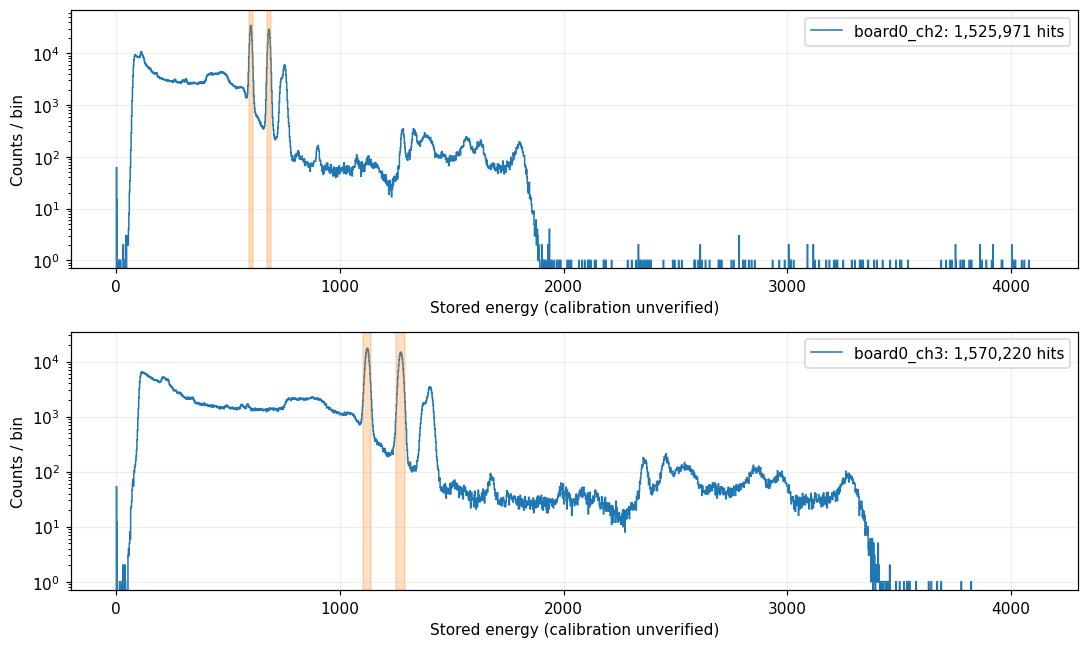

In [5]:
if SPECTRA:
    figure = analysis.plot_energy(RESULT, SETTINGS)
    analysis.save_figure(figure, OUTPUT_DIR, "energy_spectra")
    display(figure)
    plt.close(figure)
else:
    print("No hits: no energy spectrum to plot")

## 5. 能量峰的局部拟合与残差

示例模型是 **Gaussian + 非负常数背景**，使用计数的 Poisson 似然，并在每个 bin 内积分模型。ROOT 选项为 `L I R S Q N`；方法依据见 [ROOT 拟合说明](https://root.cern.ch/manual/fitting/) 和 [TH1::Fit 文档](https://root.cern.ch/doc/master/classTH1.html)。

报告峰位、σ、FWHM = 2√(2 ln 2) σ 及协方差导出的统计误差；不把收敛等同于模型正确。下方残差为 `(观测 − 模型)/√模型`，并保存 Poisson deviance/ndf。大于 2 时标记“检查模型”作为提示，这不是严格的物理验收阈值。背景趋势、峰尾及区间选择可能带来未计入统计误差的系统差异。

这些区间针对峰核。可以把 ch2 第一峰改成 `[574, 630]` 检查更宽区间中的峰尾和背景，观察宽度与残差如何变化。

峰,拟合区间,峰位 ± 统计误差,FWHM ± 统计误差,单位,deviance/ndf,提示
ch2_peak1,"[590.0, 614.0]",601.3283 ± 0.0121,11.0455 ± 0.0523,stored units,2.40,inspect_model
ch2_peak2,"[670.0, 696.0]",682.5795 ± 0.0130,11.8675 ± 0.0562,stored units,1.44,inspect_residuals
ch3_peak1,"[1100.0, 1144.0]",1122.2650 ± 0.0225,19.5777 ± 0.0906,stored units,2.67,inspect_model
ch3_peak2,"[1250.0, 1296.0]",1272.2681 ± 0.0240,20.9929 ± 0.0995,stored units,0.84,inspect_residuals


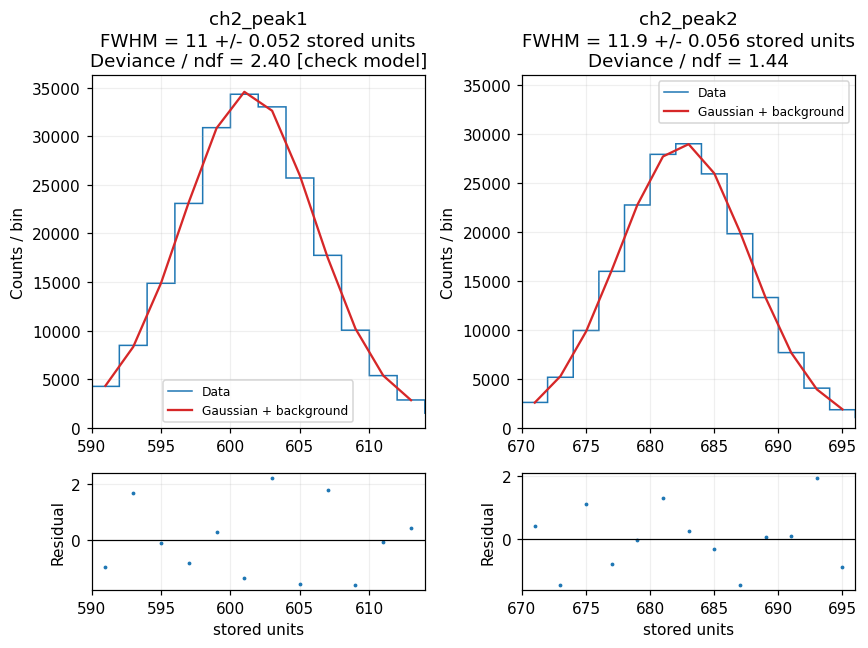

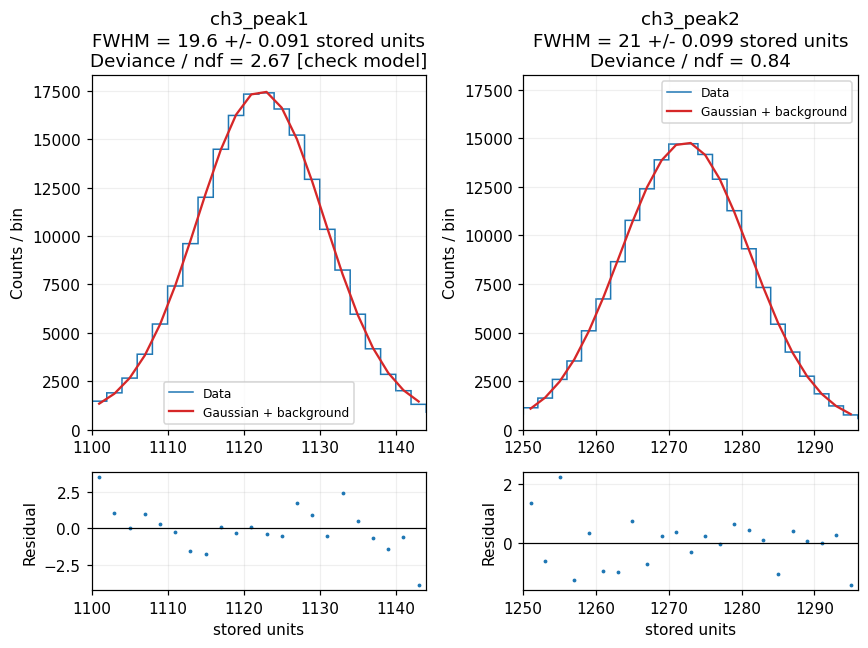

In [6]:
FITS = {}
energy_items = []
for peak in ENERGY_PEAKS:
    key = peak["spectrum"]
    if key not in SPECTRA:
        print(f"Skipping {peak['name']}: spectrum {key} is absent")
        continue
    fit = analysis.fit_peak(SPECTRA[key], peak["range"], "stored units")
    FITS[peak["name"]] = fit
    energy_items.append((peak["name"], SPECTRA[key], fit))

def fit_rows(items):
    rows = []
    for name, fit in items:
        if fit["usable"]:
            rows.append([name, fit["range"], f'{fit["mean"]:.4f} ± {fit["mean_error"]:.4f}',
                         f'{fit["fwhm"]:.4f} ± {fit["fwhm_error"]:.4f}',
                         fit["unit"], f'{fit["deviance_per_ndf"]:.2f}', fit["quality_flag"]])
        else:
            rows.append([name, fit["range"], "—", "—", fit["unit"], "—", fit["reason"]])
    return rows

FIT_HEADERS = ["峰", "拟合区间", "峰位 ± 统计误差", "FWHM ± 统计误差", "单位", "deviance/ndf", "提示"]
table(FIT_HEADERS, fit_rows(FITS.items()))
# Two fits per figure keeps the saved notebook readable on a normal screen.
for index in range(0, len(energy_items), 2):
    figure = analysis.plot_fits(energy_items[index:index + 2])
    analysis.save_figure(figure, OUTPUT_DIR, f"energy_fits_{index // 2 + 1}")
    display(figure)
    plt.close(figure)

## 6. 时间差谱与拟合

灰/蓝色谱包含指定通道对的全部双重事件，另一条谱仅包含两通道均通过能量门的事件。时间差由整数 ps 先相减，再转换为 ns，避免先转换大时间戳时丢失精度。

当前样本的负峰位表示在文件存储的时间戳中 B 通道较早。这是该文件及当前筛选下的相对偏移，不能直接认定为新的硬件时间校正值。

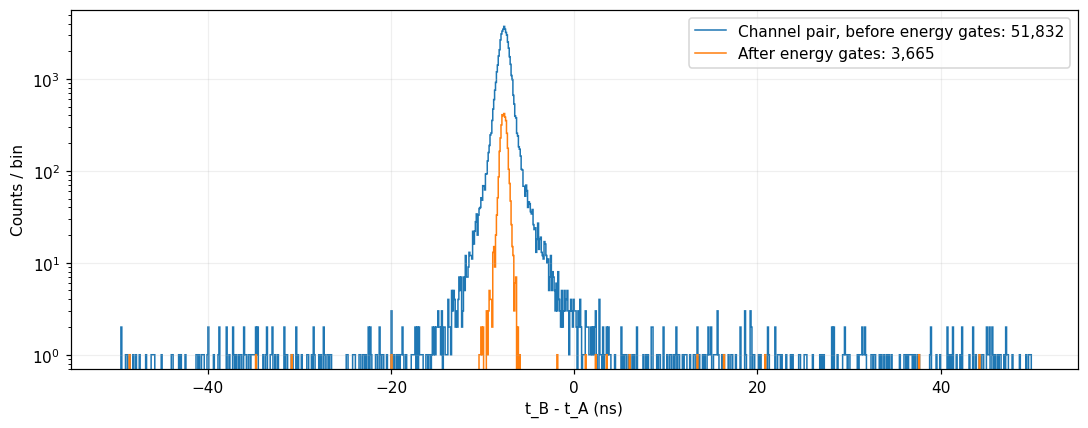

峰,拟合区间,峰位 ± 统计误差,FWHM ± 统计误差,单位,deviance/ndf,提示
time_difference,"[-9.5, -5.5]",-7.6819 ± 0.0059,0.7943 ± 0.0121,ns,2.50,inspect_model


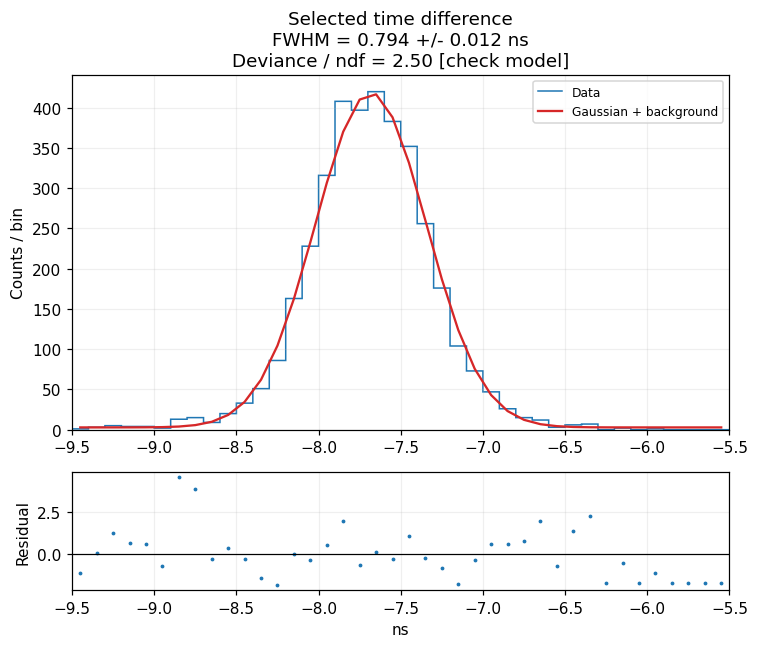

In [7]:
figure = analysis.plot_timing(RESULT)
analysis.save_figure(figure, OUTPUT_DIR, "time_difference")
display(figure)
plt.close(figure)

TIME_FIT = analysis.fit_peak(RESULT.selected_times, TIME_FIT_RANGE, "ns")
FITS["time_difference"] = TIME_FIT
table(FIT_HEADERS, fit_rows([("time_difference", TIME_FIT)]))
figure = analysis.plot_fits([("Selected time difference", RESULT.selected_times, TIME_FIT)])
analysis.save_figure(figure, OUTPUT_DIR, "time_fit")
display(figure)
plt.close(figure)

## 7. 检查时间拟合区间的影响

同一份入选时间差谱在几个相邻区间中分别拟合，比较 FWHM 变化。显示的 `±` 只包含该模型内部的统计误差，不包含区间、背景、峰尾、能量门或分箱选择造成的差异。若提示检查模型，请结合残差考虑峰尾或其他背景模型，而非只读取最小的宽度。

这里的 FWHM 是**两通道时间差分布的局部模型宽度**。只有已验证两个通道独立且具有相同时间分辨率等前提，才能考虑除以 √2 得到单通道指标；本笔记不作该换算。当前能量门合并了多个峰窗口，进一步比较时也可拆分不同能量组合。

In [8]:
RANGE_FITS = {}
for bounds in TIME_RANGE_CHECKS:
    label = f"time_range_{bounds[0]:g}_{bounds[1]:g}"
    RANGE_FITS[label] = analysis.fit_peak(RESULT.selected_times, bounds, "ns")
FITS.update(RANGE_FITS)
table(FIT_HEADERS, fit_rows(RANGE_FITS.items()))
widths = [fit["fwhm"] for fit in RANGE_FITS.values() if fit["usable"]]
if widths:
    print(f"FWHM range over these fits: {min(widths):.4f} to {max(widths):.4f} ns")
    print("This spread is a sensitivity check, not a systematic-error estimate.")

峰,拟合区间,峰位 ± 统计误差,FWHM ± 统计误差,单位,deviance/ndf,提示
time_range_-9_-6,"[-9.0, -6.0]",-7.6816 ± 0.0059,0.7769 ± 0.0126,ns,2.15,inspect_model
time_range_-9.5_-5.5,"[-9.5, -5.5]",-7.6819 ± 0.0059,0.7943 ± 0.0121,ns,2.50,inspect_model
time_range_-10_-5,"[-10.0, -5.0]",-7.6823 ± 0.0060,0.8080 ± 0.0119,ns,2.74,inspect_model


FWHM range over these fits: 0.7769 to 0.8080 ns
This spread is a sensitivity check, not a systematic-error estimate.


## 8. 导出可追溯结果

保存 `results.json`、`fits.csv`、`histograms.root` 和 PNG/PDF 图像。JSON 包含输入校验值、版本和源码快照标识、全部筛选条件、计数、拟合范围、协方差及质量指标。大数据产物位于被 Git 忽略的 `results/`，Notebook 自身保留小型表格和图像便于阅读。

In [9]:
NOTES = {
    "energy_unit": "Stored units; calibration of the historical sorted file is unverified",
    "energy_peak_settings": ENERGY_PEAKS,
    "time_fit_range": TIME_FIT_RANGE,
    "time_range_checks": TIME_RANGE_CHECKS,
    "historical_comparison": HISTORICAL,
    "time_width_interpretation": "Two-channel dt width; no conversion to single-detector resolution",
    "uncertainty": "Fit covariance only; model, range, gates, binning and calibration systematics excluded",
    "known_upstream_limits": "Historical sorting provenance unknown; board preservation and timestamp precision need separate validation",
}
REPORT = analysis.export_results(OUTPUT_DIR, PROVENANCE, SETTINGS, RESULT, FITS, NOTES)
assert analysis.file_identity(SORTED_INPUT)["sha256"] == PROVENANCE["input_sorted"]["sha256"]
if HISTORICAL is not None:
    assert analysis.file_identity(HISTORICAL_BUILT)["sha256"] == HISTORICAL["sha256"]
print("Saved:", OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"  {path.name:28s} {path.stat().st_size:>12,} bytes")
print("Input and historical event files are unchanged.")

Saved: /media/sf_works/LaBr3/results/DT5730_DPP_PSD_run0009_20260928T090457Z_0q6xqbwn
  build.log                             633 bytes
  energy_fits_1.pdf                  20,886 bytes
  energy_fits_1.png                 117,986 bytes
  energy_fits_2.pdf                  22,149 bytes
  energy_fits_2.png                 122,701 bytes
  energy_spectra.pdf                 45,961 bytes
  energy_spectra.png                115,450 bytes
  fits.csv                            1,497 bytes
  histograms.root                    13,118 bytes
  results.json                       23,354 bytes
  run0009_build.root             43,381,987 bytes
  time_difference.pdf                20,958 bytes
  time_difference.png                53,044 bytes
  time_fit.pdf                       19,839 bytes
  time_fit.png                       81,846 bytes
Input and historical event files are unchanged.


## 继续自行分析

- 修改第 1 节的能量门后，运行参数单元，再从第 3 节运行到底，无需重新构建事件；第 8 节会更新这次目录中的结果。
- 只改拟合区间时，运行参数单元，再从第 5 节运行到底。修改时间分箱后必须先重新运行第 3 节。
- 更换设备、运行编号或输入文件后，从头运行，并调整该样本的通道和峰区间。
- 直接使用 `SPECTRA["board0_ch2"]`、`RESULT.selected_times` 等 ROOT 直方图编写自己的代码；`analysis.histogram_arrays(...)` 可取得 NumPy 的 bin 边界与计数数组。
- 当前能量刻度、探测器和通道的对应、放射源、阈值及采集条件仍待实验记录补充。用于正式物理结果前，需要检验上游处理、模型和系统误差。

共享实现：[EventAnalysis.h](../analysis/EventAnalysis.h)、[notebook_analysis.py](../analysis/notebook_analysis.py)。程序回归检查见 [tests/README.md](../tests/README.md)，前一步事件构建修复见 [Notebook 01](01_event_building_and_regression.ipynb)。